# 페어픽 박람회 데이터 분석

'언제, 어디서, 어떤 박람회가 많이 열리는가'를 페어픽에 모인 데이터로 살펴본다.
공개·숨김(지난 행사) 박람회를 함께 세고, 검수 전 초안은 뺀다. 데이터가 쌓일수록 다시 실행해 갱신한다.

In [1]:
import os
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
from sqlalchemy import create_engine

# matplotlib 기본 폰트에는 한글이 없어 글자가 네모로 깨진다 (레퍼런스 17장 트러블슈팅)
plt.rcParams["font.family"] = "Malgun Gothic"  # macOS/Linux 는 "AppleGothic" / "NanumGothic"
plt.rcParams["axes.unicode_minus"] = False
for side in ("top", "right"):
    plt.rcParams[f"axes.spines.{side}"] = False

def database_url():
    if "DATABASE_URL" in os.environ:
        return os.environ["DATABASE_URL"]
    for line in (Path.cwd().parent / ".env").read_text(encoding="utf-8").splitlines():
        if line.startswith("DATABASE_URL="):
            return line.split("=", 1)[1]
    raise RuntimeError("DATABASE_URL 이 없어요")

engine = create_engine(database_url())
df = pd.read_sql(
    "SELECT f.id, f.title, f.start_date, f.end_date, f.price_onsite, f.price_prereg, f.public_access, "
    "       c.code AS category_code, c.name AS category, v.name AS venue, v.region "
    "FROM fairs f JOIN categories c ON c.id = f.category_id JOIN venues v ON v.id = f.venue_id "
    "WHERE f.status IN ('published', 'hidden')",
    engine,
    parse_dates=["start_date", "end_date"],
)
df["month"] = df["start_date"].dt.to_period("M")
df["days"] = (df["end_date"] - df["start_date"]).dt.days + 1
df["free"] = (df["price_onsite"] == 0) | (df["price_prereg"] == 0)
# 맑은 고딕에는 가운뎃점(·) 글자가 없어 빈칸으로 보인다. 한글 가운뎃점(ㆍ)으로 바꿔 표시한다
df["category"] = df["category"].str.replace("·", "ㆍ")
print(f"박람회 {len(df)}개, 기간 {df['start_date'].min():%Y-%m-%d} ~ {df['end_date'].max():%Y-%m-%d}")

박람회 30개, 기간 2026-04-15 ~ 2026-12-27


## 1. 월별로 언제 많이 열리나

카테고리 색은 서비스의 통계 화면과 같다 (카테고리마다 고정).

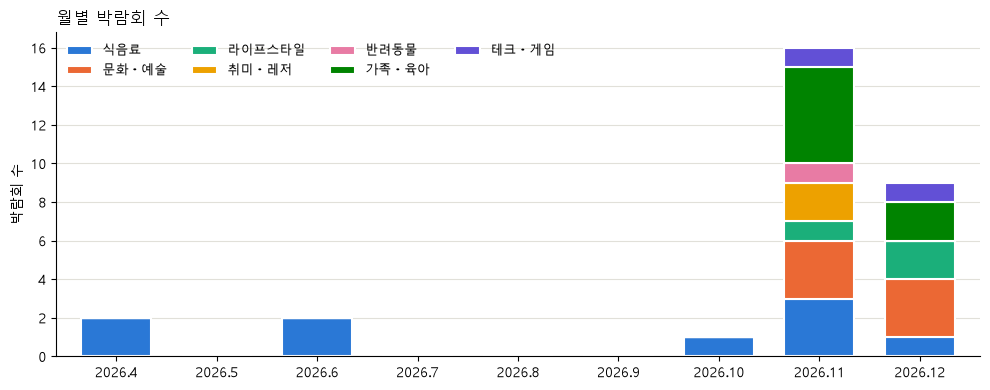

category,식음료,문화ㆍ예술,라이프스타일,취미ㆍ레저,반려동물,가족ㆍ육아,테크ㆍ게임,합계
2026.4,2,0,0,0,0,0,0,2
2026.5,0,0,0,0,0,0,0,0
2026.6,2,0,0,0,0,0,0,2
2026.7,0,0,0,0,0,0,0,0
2026.8,0,0,0,0,0,0,0,0
2026.9,0,0,0,0,0,0,0,0
2026.10,1,0,0,0,0,0,0,1
2026.11,3,3,1,2,1,5,1,16
2026.12,1,3,2,0,0,2,1,9


In [2]:
COLORS = {"식음료": "#2a78d6", "문화ㆍ예술": "#eb6834", "라이프스타일": "#1baf7a", "취미ㆍ레저": "#eda100",
          "반려동물": "#e87ba4", "가족ㆍ육아": "#008300", "테크ㆍ게임": "#6250d6"}
monthly = df.pivot_table(index="month", columns="category", values="id", aggfunc="count", fill_value=0)
# 박람회가 없는 달도 0 으로 보여 달 간격을 고르게 한다
monthly = monthly.reindex(pd.period_range(monthly.index.min(), monthly.index.max(), freq="M"), fill_value=0)
monthly = monthly[[c for c in COLORS if c in monthly.columns]]
monthly.index = [f"{p.year}.{p.month}" for p in monthly.index]  # 막대 축 라벨: 2026.4
ax = monthly.plot(kind="bar", stacked=True, figsize=(10, 4), width=0.7, edgecolor="white", linewidth=1.5,
                  color=[COLORS[c] for c in monthly.columns])
ax.set_title("월별 박람회 수", loc="left")
ax.set_xlabel(""); ax.set_ylabel("박람회 수")
ax.tick_params(axis="x", rotation=0)
ax.legend(frameon=False, ncols=4, fontsize=9, loc="upper left")
ax.grid(axis="y", color="#e1e0d9"); ax.set_axisbelow(True)
plt.tight_layout(); plt.show()
monthly.assign(합계=monthly.sum(axis=1))

## 2. 카테고리별 비중, 평균 기간, 무료 비율

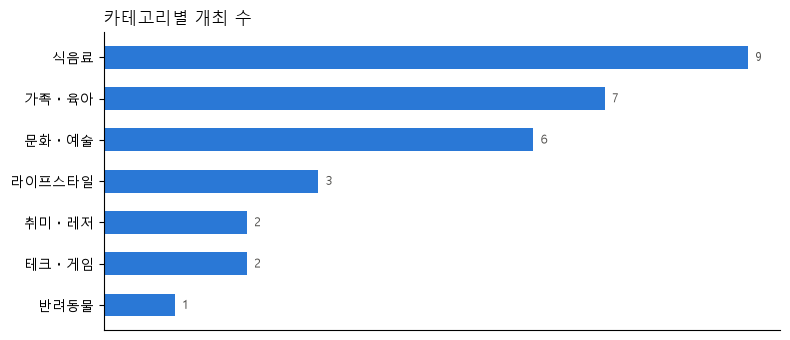

,개최수,평균기간_일,무료비율,비중
category,,,,
식음료,9,3.7,0%,30%
가족ㆍ육아,7,4.0,29%,23%
문화ㆍ예술,6,4.2,0%,20%
라이프스타일,3,4.0,33%,10%
취미ㆍ레저,2,3.0,0%,7%
테크ㆍ게임,2,3.5,0%,7%
반려동물,1,3.0,0%,3%


In [3]:
by_cat = (
    df.groupby("category")
    .agg(개최수=("id", "count"), 평균기간_일=("days", "mean"), 무료비율=("free", "mean"))
    .sort_values("개최수", ascending=False)
)
by_cat["비중"] = by_cat["개최수"] / by_cat["개최수"].sum()

fig, ax = plt.subplots(figsize=(8, 3.5))
ax.barh(by_cat.index[::-1], by_cat["개최수"][::-1], color="#2a78d6", height=0.55)
for y, v in enumerate(by_cat["개최수"][::-1]):
    ax.text(v + 0.1, y, str(v), va="center", fontsize=9, color="#52514e")
ax.set_title("카테고리별 개최 수", loc="left"); ax.set_xticks([])
plt.tight_layout(); plt.show()
by_cat.style.format({"평균기간_일": "{:.1f}", "무료비율": "{:.0%}", "비중": "{:.0%}"})

## 3. 전시장별로 어떤 박람회가 많이 열리나

In [4]:
by_venue = pd.crosstab(df["venue"], df["category"])
by_venue["합계"] = by_venue.sum(axis=1)
by_venue["가장 많은 카테고리"] = by_venue.drop(columns="합계").idxmax(axis=1)
by_venue.sort_values("합계", ascending=False)

category,가족ㆍ육아,라이프스타일,문화ㆍ예술,반려동물,식음료,취미ㆍ레저,테크ㆍ게임,합계,가장 많은 카테고리
venue,,,,,,,,,
코엑스,2,2,5,0,5,1,0,15,문화ㆍ예술
킨텍스,1,1,1,1,2,1,1,8,식음료
엑스코,1,0,0,0,1,0,0,2,가족ㆍ육아
벡스코,1,0,0,0,0,0,1,2,가족ㆍ육아
코엑스 마곡,1,0,0,0,1,0,0,2,가족ㆍ육아
수원메쎄,1,0,0,0,0,0,0,1,가족ㆍ육아


## 4. 무료로 갈 수 있는 박람회는 몇 %인가

In [5]:
known = df[df["price_onsite"].notna() | df["price_prereg"].notna()]
print(f"전체 {len(df)}개 중 무료(현장 또는 사전등록) {df['free'].sum()}개 = {df['free'].mean():.0%}")
print(f"입장료 정보가 있는 {len(known)}개 기준: 무료 {known['free'].mean():.0%}")
print("입장료를 모르는 박람회가 많을수록 이 비율은 낮게 나온다. 검수 때 입장료를 채우면 정확해진다.")

전체 30개 중 무료(현장 또는 사전등록) 3개 = 10%
입장료 정보가 있는 5개 기준: 무료 60%
입장료를 모르는 박람회가 많을수록 이 비율은 낮게 나온다. 검수 때 입장료를 채우면 정확해진다.


## 5. 지난 7년의 흐름 (지난 행사 기록)

`fair_archive` 는 전시장 공식 사이트의 지난 일정을 모은 분석 전용 테이블이다 (`python -m app.scripts.backfill_archive --from 2019 --to 2025`). 개막일 기준, 학회·회의는 뺐다.

지난 행사 2809건, 전시장 4곳


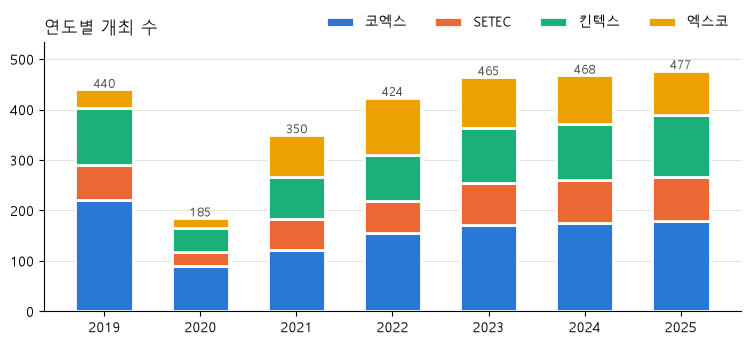

venue,코엑스,SETEC,킨텍스,엑스코,합계
year,,,,,
2019,221,69,114,36,440
2020,89,29,47,20,185
2021,121,62,83,84,350
2022,155,64,92,113,424
2023,171,83,109,102,465
2024,176,84,111,97,468
2025,179,87,124,87,477


In [6]:
arc = pd.read_sql(
    "SELECT a.title, a.start_date, a.theme, v.name AS venue, v.id AS venue_id "
    "FROM fair_archive a JOIN venues v ON v.id = a.venue_id "
    "WHERE YEAR(a.start_date) BETWEEN 2019 AND 2025",
    engine,
    parse_dates=["start_date"],
)
arc["year"] = arc["start_date"].dt.year
arc["month_no"] = arc["start_date"].dt.month
arc["theme"] = arc["theme"].str.replace("·", "ㆍ")
print(f"지난 행사 {len(arc)}건, 전시장 {arc['venue'].nunique()}곳")

# 전시장 색은 서비스 통계 화면과 같다 (전시장 id 순서로 고정)
venue_order = arc.drop_duplicates("venue").sort_values("venue_id")["venue"].tolist()
VENUE_COLORS = dict(zip(venue_order, ["#2a78d6", "#eb6834", "#1baf7a", "#eda100"], strict=False))
yearly = arc.pivot_table(index="year", columns="venue", values="title", aggfunc="count", fill_value=0)
yearly = yearly.reindex(range(2019, 2026), fill_value=0)[venue_order]

fig, ax = plt.subplots(figsize=(9, 3.5))
bottom = pd.Series(0, index=yearly.index)
for venue in venue_order:
    ax.bar(yearly.index, yearly[venue], bottom=bottom, color=VENUE_COLORS[venue], label=venue,
           edgecolor="white", linewidth=2, width=0.6)
    bottom += yearly[venue]
for x, total in bottom.items():
    ax.text(x, total + 3, f"{total}", ha="center", fontsize=9, color="#52514e")
ax.set_title("연도별 개최 수", loc="left")
ax.set_ylim(0, bottom.max() * 1.12)  # 막대 위 합계 숫자 자리
# 범례는 그래프 밖 오른쪽 위에 둬서 막대·숫자를 가리지 않는다
ax.legend(frameon=False, ncols=len(venue_order), loc="lower right", bbox_to_anchor=(1, 1))
ax.grid(axis="y", color="#e1e0d9")
ax.set_axisbelow(True)
plt.show()
yearly.assign(합계=yearly.sum(axis=1))

## 6. 주제별로 언제 많이 열리나

제목 키워드로 주제를 나눴다 (`backend/app/services/archive.py`). 7년 합계.
전시장 일정표에 섞인 입주박람회(새 아파트 입주민 행사)와 박람회가 아닌 행사(선거 개표, 공연, 면세점 행사 등), 주제를 못 찾은 '기타'는 뺀다. B2B 전시회·학술대회는 '산업ㆍ학술' 한 줄로 모았다.

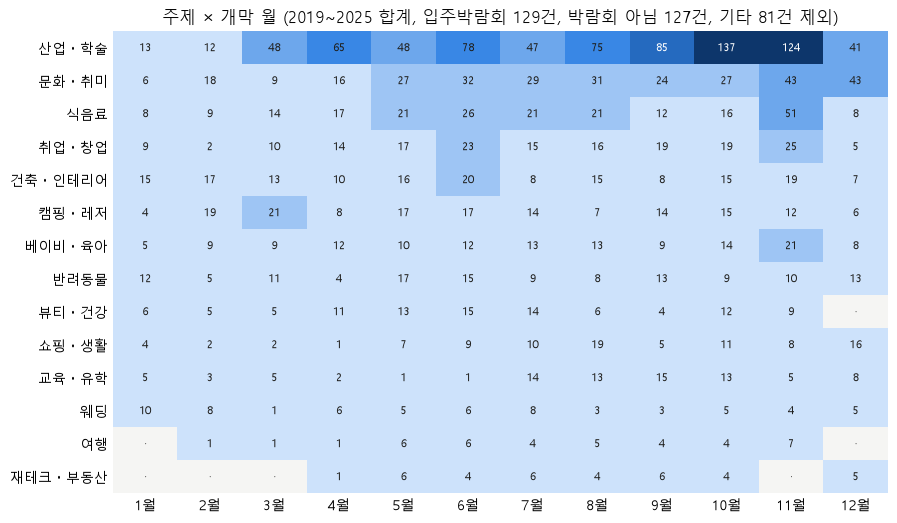

,합계,가장 많은 달
theme,,
산업ㆍ학술,773,10월
문화ㆍ취미,305,11월·12월
식음료,224,11월
취업ㆍ창업,174,11월
건축ㆍ인테리어,163,6월
캠핑ㆍ레저,154,3월
베이비ㆍ육아,135,11월
반려동물,126,5월
뷰티ㆍ건강,100,6월


In [7]:
from matplotlib.colors import ListedColormap

left_out = arc["theme"].isin(["기타", "입주박람회", "박람회 아님"])
themed = arc[~left_out]
heat = themed.pivot_table(index="theme", columns="month_no", values="title", aggfunc="count", fill_value=0)
heat = heat.reindex(columns=range(1, 13), fill_value=0)
heat = heat.loc[heat.sum(axis=1).sort_values(ascending=False).index]
# 파랑 한 가지 계열 (서비스 통계 화면과 같은 단계)
cmap = ListedColormap(["#f5f5f3", "#cde2fb", "#9ec5f4", "#6da7ec", "#3987e5", "#256abf", "#184f95", "#0d366b"])

# 0건은 회색, 나머지는 최댓값 대비 7단계 (서비스 통계 화면과 같은 계산)
vmax = heat.values.max()
level = heat.apply(lambda col: col.map(lambda n: 0 if n == 0 else 1 + min(6, int(n / vmax * 7))))
fig, ax = plt.subplots(figsize=(10, 6))
ax.imshow(level.values, cmap=cmap, vmin=0, vmax=7, aspect="auto")
ax.set_xticks(range(12), [f"{m}월" for m in range(1, 13)])
ax.set_yticks(range(len(heat)), heat.index)
for (i, j), n in pd.DataFrame(heat.values).stack().items():
    ax.text(j, i, n if n else "·", ha="center", va="center", fontsize=8,
            color="white" if level.values[i, j] >= 5 else "#1f1f1d")
for side in ("left", "bottom"):
    ax.spines[side].set_visible(False)
ax.tick_params(length=0)
left_counts = arc.loc[left_out, "theme"].value_counts()
ax.set_title("주제 × 개막 월 (2019~2025 합계, " + ", ".join(f"{k} {v}건" for k, v in left_counts.items()) + " 제외)")
plt.show()

peaks = heat.apply(lambda r: "·".join(f"{m}월" for m in r.index[r == r.max()]), axis=1)
pd.DataFrame({"합계": heat.sum(axis=1), "가장 많은 달": peaks})

## 정리

- 데이터는 수집 워커가 매일 쌓는다. 1단계를 일찍 배포할수록 분석할 거리가 많아진다.
- 지난 행사는 서비스 목록과 섞지 않고 `fair_archive` 에 따로 모아 추이 분석에만 쓴다. 카테고리·입장료가 없어 제목 키워드로 주제를 나눴다.
- 연도별 막대에서 2020~2021년(코로나19) 감소와 회복을, 주제 × 월 표에서 박람회 성수기를 볼 수 있다.